# Лабораторная работа № 1. Нейронные сети. Задача 2.
## Обучение полносвязных нейронных сетей: классификаторы и регрессор
**Вариант 5 :**
| Задача | Набор данных | Целевой признак |
|---|---|---|
| Бинарная классификация | Diabetes Health Indicators | `Diabetes_012` → 0 — нет диабета, 1 — преддиабет/диабет (значения 1 и 2 объединены) |
| Многоклассовая классификация | Body Performance | `class` (A, B, C, D) |
| Регрессия | White wine Quality | `quality` |

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import tensorflow as tf
import seaborn as sns
import keras
import math
from keras import layers, regularizers, callbacks
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, label_binarize
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, recall_score, precision_score,
    f1_score, balanced_accuracy_score, accuracy_score, roc_auc_score, roc_curve, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, classification_report)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.dummy import DummyClassifier, DummyRegressor

SEED = 42
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

random.seed(SEED);
np.random.seed(SEED);
tf.keras.utils.set_random_seed(SEED)


In [3]:
def split_dataset(X, y, stratify=True):

    # Правильно разбивает датасет на train/val/test в пропорции 70/15/15

    s = y if stratify else None
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(
        X, y, 
        test_size=1 - TRAIN_FRAC, 
        random_state=SEED, 
        stratify=s
    )
    
    s = y_tmp if stratify else None
    val_ratio_of_tmp = TEST_FRAC / (VAL_FRAC + TEST_FRAC)
    
    X_va, X_te, y_va, y_te = train_test_split(
        X_tmp, y_tmp, 
        test_size=val_ratio_of_tmp, 
        random_state=SEED, 
        stratify=s
    )

    return X_tr, X_va, X_te, y_tr, y_va, y_te

def preprocess_datasets(X_tr, X_va, X_te):

    # Выполняет импутацию (медиана/мода), One-Hot кодирование и StandardScaler.
    # Все параметры (медианы, средние, категории) обучаются ТОЛЬКО на train выборке.
    
    X_tr = X_tr.copy()
    X_va = X_va.copy()
    X_te = X_te.copy()

    num_cols = X_tr.select_dtypes(include="number").columns.tolist()
    cat_cols = X_tr.select_dtypes(include=["object", "category", "string"]).columns.tolist()
    
    all_processed = num_cols + cat_cols
    extra_cols = [c for c in X_tr.columns if c not in all_processed]
    cat_cols.extend(extra_cols)


    num_pipeline = Pipeline([
        ("imp", SimpleImputer(strategy="median", add_indicator=True)), 
        ("sc", StandardScaler())
    ])

    cat_pipeline = Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent", add_indicator=True)),
        ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    
    preprocessor = ColumnTransformer([
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)
    ])
    
    X_tr_processed = preprocessor.fit_transform(X_tr).astype("float32")
    X_va_processed = preprocessor.transform(X_va).astype("float32")
    X_te_processed = preprocessor.transform(X_te).astype("float32")
    
    print(f"Предобработка завершена:")
    print(f"  Числовых признаков: {len(num_cols)}")
    print(f"  Категориальных признаков: {len(cat_cols)}")
    print(f"  Итоговая размерность матрицы (кол-во колонок): {X_tr_processed.shape[1]}")
    
    return X_tr_processed, X_va_processed, X_te_processed, preprocessor


In [4]:
def plot_histories(hist_dict, title):
    # Рисует кривые обучения (train/val loss) для каждой модели из hist_dict.

    names = list(hist_dict)
    n = len(names)
    ncols = min(3, n)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.2 * nrows), squeeze=False)

    for ax in axes.ravel():          # спрятать лишние оси
        ax.set_visible(False)

    for ax, name in zip(axes.ravel(), names):
        h = hist_dict[name]
        ep = range(1, len(h["loss"]) + 1)
        ax.plot(ep, h["loss"], label="train")
        ax.plot(ep, h["val_loss"], label="validation")
        ax.set_title(name)
        ax.set_xlabel("Эпоха"); ax.set_ylabel("Loss")
        ax.legend(); ax.grid(alpha=0.3)
        ax.set_visible(True)

    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

def build_mlp(cfg, input_dim, task, n_classes=None):
    reg = regularizers.l2(cfg["l2"]) if cfg.get("l2", 0) > 0 else None
    
    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for units in cfg["hidden"]:
        model.add(layers.Dense(units, activation=cfg["act"], kernel_regularizer=reg))
        if cfg.get("dropout", 0) > 0:
            model.add(layers.Dropout(cfg["dropout"]))
            
    if task == "regression":
        model.add(layers.Dense(1))
        loss = "mse"
    elif task == "binary":
        model.add(layers.Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    elif task == "multiclass":
        if n_classes is None:
            raise ValueError("Параметр 'n_classes' обязателен для мультиклассовой классификации (task='multiclass').")
        model.add(layers.Dense(n_classes, activation="softmax"))
        loss = "sparse_categorical_crossentropy"
    else:
        raise ValueError(f"Неизвестный тип задачи: '{task}'. Допустимые: 'regression', 'binary', 'multiclass'.")
        
    lr = cfg["lr"]
    opt_name = cfg["opt"].lower()
    
    if opt_name == "adam":
        optimizer = keras.optimizers.Adam(learning_rate=lr)
    elif opt_name == "rmsprop":
        optimizer = keras.optimizers.RMSprop(learning_rate=lr)
    elif opt_name == "sgd":
        optimizer = keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    else:
        raise ValueError(f"Неизвестный оптимизатор: '{opt_name}'. Допустимые: 'adam', 'rmsprop', 'sgd'.")
        
    model.compile(optimizer=optimizer, loss=loss)
    
    return model

## 2. Многоклассовая классификация: Body Performance
Классы A, B, C, D кодируются числами; признак `gender` — категориальный (One-Hot).

In [5]:
body = pd.read_csv("bodyPerformance.csv")

print("--- 1. Первые 5 строк датасета ---")
display(body.head())

print("--- 2. Информация и пропущенные значения ---")
print("Размер:", body.shape, "| пропусков:", int(body.isna().sum().sum()), "| полных дубликатов:", int(body.duplicated().sum()))
print("\nИсходное распределение class:\n", body["class"].value_counts().sort_index())

print("--- 3. Описательные статистики ---")
display(body.describe().T)

vc = body["class"].value_counts().sort_index()
print("\nКлассы:\n", pd.DataFrame({"n": vc, "доля": (vc / len(body)).round(4)}))

print("\n--- 4. Распределение целевой переменной (target) ---")
counts = body["class"].value_counts()
percentages = body["class"].value_counts(normalize=True) * 100
target_df = pd.DataFrame({'Количество': counts, 'Процент (%)': percentages})
display(target_df)

le = LabelEncoder()
y_m = le.fit_transform(body["class"])
CLASSES = list(le.classes_)
K = len(CLASSES)
X = body.drop(columns=["class"])


Xtr_df, Xva_df, Xte_df, ytr_m, yva_m, yte_m = split_dataset(X, y_m, stratify=True)

# Затем масштабируем/предобрабатываем признаки
Xtr_m, Xva_m, Xte_m, _ = preprocess_datasets(Xtr_df, Xva_df, Xte_df)


print("\n--- 5. Контроль разбиения и веса классов ---")

print("Распределение классов в train:", np.bincount(ytr_m) / len(ytr_m))

classes_in_train = np.unique(ytr_m)
weights = compute_class_weight(class_weight='balanced', classes=classes_in_train, y=ytr_m)
cw = dict(zip(classes_in_train, weights))

print("class_weight:", {k: round(v, 3) for k, v in cw.items()})


--- 1. Первые 5 строк датасета ---


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


--- 2. Информация и пропущенные значения ---
Размер: (13393, 12) | пропусков: 0 | полных дубликатов: 1

Исходное распределение class:
 class
A    3348
B    3347
C    3349
D    3349
Name: count, dtype: int64
--- 3. Описательные статистики ---


,count,mean,std,min,25%,50%,75%,max
age,13393.0,36.775106,13.625639,21.0,25.0,32.0,48.0,64.0
height_cm,13393.0,168.559807,8.426583,125.0,162.4,169.2,174.8,193.8
weight_kg,13393.0,67.447316,11.949666,26.3,58.2,67.4,75.3,138.1
body fat_%,13393.0,23.240165,7.256844,3.0,18.0,22.8,28.0,78.4
diastolic,13393.0,78.796842,10.742033,0.0,71.0,79.0,86.0,156.2
systolic,13393.0,130.234817,14.713954,0.0,120.0,130.0,141.0,201.0
gripForce,13393.0,36.963877,10.624864,0.0,27.5,37.9,45.2,70.5
sit and bend forward_cm,13393.0,15.209268,8.456677,-25.0,10.9,16.2,20.7,213.0
sit-ups counts,13393.0,39.771224,14.276698,0.0,30.0,41.0,50.0,80.0
broad jump_cm,13393.0,190.129627,39.868000,0.0,162.0,193.0,221.0,303.0



Классы:
           n    доля
class              
A      3348  0.2500
B      3347  0.2499
C      3349  0.2501
D      3349  0.2501

--- 4. Распределение целевой переменной (target) ---


,Количество,Процент (%)
class,,
C,3349,25.005600
D,3349,25.005600
A,3348,24.998133
B,3347,24.990667


Предобработка завершена:
  Числовых признаков: 10
  Категориальных признаков: 1
  Итоговая размерность матрицы (кол-во колонок): 12

--- 5. Контроль разбиения и веса классов ---
Распределение классов в train: [0.25002667 0.24992    0.25002667 0.25002667]
class_weight: {np.int64(0): np.float64(1.0), np.int64(1): np.float64(1.0), np.int64(2): np.float64(1.0), np.int64(3): np.float64(1.0)}


| Имя признака | Перевод названия | Тип данных | Описание и диапазон значений |
| :--- | :--- | :---: | :--- |
| **class** | Класс физ. развития | Категориальный | **Целевой признак (Target)**. 4 уровня подготовки: **A** (лучший), **B**, **C**, **D** (худший). Перед подачей в MLP кодируется в числа `0, 1, 2, 3`. |
| **age** | Возраст | Числовой | Возраст респондента в годах (от 21 до 64 лет). Среднее значение — 36.8 лет. |
| **gender** | Пол | Категориальный | Пол респондента: `M` (мужской) или `F` (женский). Преобразуется в числовой вид через кодирование. |
| **height_cm** | Рост (см) | Числовой | Рост в сантиметрах (от 125.0 до 193.8 см). |
| **weight_kg** | Вес (кг) | Числовой | Масса тела в килограммах (от 26.3 до 138.1 кг). |
| **body fat_%** | Процент жира | Числовой | Процент содержания жировой ткани в организме (от 3.0% до 78.4%). Ключевой маркер состава тела. |
| **diastolic** | Диастолическое АД | Числовой | «Нижнее» артериальное давление (мм рт. ст.). *В данных содержатся аномальные нулевые значения.* |
| **systolic** | Систолическое АД | Числовой | «Верхнее» артериальное давление (мм рт. ст.). Среднее значение по выборке — 130.2 мм рт. ст. |
| **gripForce** | Сила сжатия кисти | Числовой | Результат кистевой динамометрии в килограммах (от 0.0 до 70.5 кг). Измеряет абсолютную силу мышц рук. |
| **sit and bend forward_cm** | Наклон вперед сидя | Числовой | Тест на гибкость позвоночника (в см). Отрицательные значения (до -25.0) нормальны. *Присутствует выброс 213.0 см.* |
| **sit-ups counts** | Подъемы туловища | Числовой | Количество повторений упражнения на пресс за фиксированное время (от 0 до 80 раз). Измеряет выносливость. |
| **broad jump_cm** | Прыжок в длину | Числовой | Длина прыжка с места в сантиметрах (от 0 до 303 см). Характеризует взрывную силу ног. |


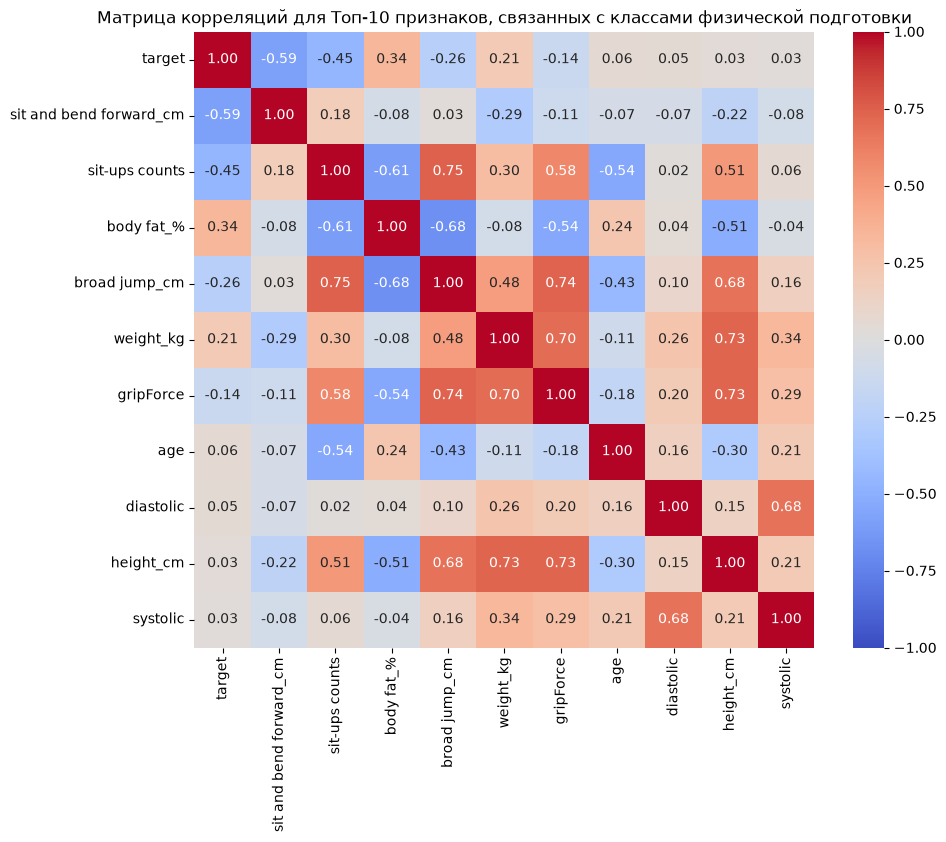

In [6]:
train_df = Xtr_df.copy()
train_df['target'] = ytr_m
full_corr = train_df.corr(method='pearson', numeric_only=True)

top_features = full_corr['target'].abs().sort_values(ascending=False).head(11).index

plt.figure(figsize=(10, 8))
sns.heatmap(full_corr.loc[top_features, top_features], annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций для Топ-10 признаков, связанных с классами физической подготовки")
plt.show()

#### 1. Взаимосвязь признаков с целевой переменной (`target`)
Целевая переменная демонстрирует сильную и умеренную линейную связь с ключевыми спортивными показателями:
*   **`sit and bend forward_cm` (Наклон вперед сидя): `-0.59`** — наиболее сильная обратная корреляция. Это указывает на то, что с улучшением гибкости (увеличением значения в см) числовая метка класса снижается. Поскольку наилучший класс физической формы — **A** (кодируется как `0`), отрицательный коэффициент подтверждает, что развитая гибкость напрямую связана с более высоким уровнем физического развития.
*   **`sit-ups counts` (Подъемы туловища): `-0.45`** — сильная обратная связь. Чем больше повторений на пресс выполняет человек, тем ближе он к лучшему классу физподготовки (ближе к `0`).
*   **`body fat_%` (Процент жира): `0.34`** — прямая корреляция. Рост проценты жира в организме линейно связан с ухудшением класса физического развития (сдвиг в сторону классов **C** и **D**, кодируемых как `2` и `3`).
*   **`broad jump_cm` (Прыжок в длину): `-0.26`** и **`weight_kg` (Вес): `0.21`** — взрывная сила ног и оптимальный вес также вносят весомый вклад в общую оценку.

Такие признаки, как **`age` (0.06)**, **`diastolic` (0.05)**, **`height_cm` (0.03)** и **`systolic` (0.03)**, практически не имеют прямой *линейной* связи с итоговым классом. Тем не менее, они важны для нейросети, так как влияют на другие показатели нелинейно.

#### 2. Анализ мультиколлинеарности и сильных взаимосвязей
В отличие от предыдущего датасета, здесь присутствует группа сильно взаимосвязанных признаков (коэффициенты корреляции близки к критическим или превышают `0.70`). Это объясняется физиологическими особенностями человека:
*   **Связь веса, роста и силы:** Наблюдается выраженная коллинеарность между парами `weight_kg` и `height_cm` (`0.73`), `gripForce` и `weight_kg` (`0.70`), а также `gripForce` и `height_cm` (`0.73`). Более высокие и крупные люди обладают большей абсолютной силой сжатия кисти.
*   **Связь прыжка в длину и физических параметров:** Признак `broad jump_cm` сильно коррелирует с силой кисти `gripForce` (`0.74`) и количеством подъемов туловища `sit-ups counts` (`0.75`), но имеет выраженную обратную связь с процентом жира `body fat_%` (`-0.68`). Это показывает, что прыгучесть (взрывная сила) напрямую зависит от общей мышечной массы и снижается при избыточном весе.
*   **Показатели давления:** Давление `diastolic` и `systolic` ожидаемо связано между собой (`0.68`).

#### Вывод для проектирования MLP:
Наличие сильных корреляций (до `0.75`) между антропометрическими параметрами и спортивными результатами указывает на избыточность некоторых линейных признаков. Полносвязная нейронная сеть (MLP) за счёт скрытых слоёв и нелинейных функций активации (`ReLU`) способна эффективно комбинировать эти коррелирующие факторы, извлекая из них скрытые паттерны (например, вычисляя условное соотношение веса к силе).


In [13]:
def multi_eval(y, proba, k):
    pred = proba.argmax(1)
    rep = classification_report(y, pred, target_names=CLASSES, output_dict=True, zero_division=0)
    Y = label_binarize(y, classes=list(range(k)))
    aucs = [roc_auc_score(Y[:, i], proba[:, i]) for i in range(k)]          # One-vs-Rest
    return dict(rep=rep, bal=balanced_accuracy_score(y, pred), aucs=aucs, macro_auc=float(np.mean(aucs)), acc=accuracy_score(y, pred), pred=pred)

mc = {}
mc_val = {}
mc_hist = {}
mc_proba = {}
mc_models = {}

dummy_mc = DummyClassifier(strategy="prior")
history = dummy_mc.fit(Xtr_m, ytr_m)

proba_va = dummy_mc.predict_proba(Xva_m)
proba_te = dummy_mc.predict_proba(Xte_m)

mc_models["Dummy (prior)"] = dummy_mc
mc_val["Dummy (prior)"] = multi_eval(yva_m, proba_va, K)
mc["Dummy (prior)"] = multi_eval(yte_m, proba_te, K)
mc_proba["Dummy (prior)"] = proba_te

print(classification_report(yte_m, mc["Dummy (prior)"]["pred"], target_names=CLASSES, digits=4))
keras.backend.clear_session()

              precision    recall  f1-score   support

           A     0.2499    1.0000    0.3998       502
           B     0.0000    0.0000    0.0000       502
           C     0.0000    0.0000    0.0000       503
           D     0.0000    0.0000    0.0000       502

    accuracy                         0.2499      2009
   macro avg     0.0625    0.2500    0.1000      2009
weighted avg     0.0624    0.2499    0.0999      2009



d:\Code\GitHubRep\neural_networks_labs\lab1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Code\GitHubRep\neural_networks_labs\lab1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Code\GitHubRep\neural_networks_labs\lab1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier,

In [14]:
cfg_mlp1 = dict(name="MLP-1", hidden=[32], act="relu", opt="adam", lr=1e-3, batch=512, dropout=0.0, l2=0.0)

model = build_mlp(cfg_mlp1, Xtr_m.shape[1], "multiclass", n_classes=K)

es = keras.callbacks.EarlyStopping(
    monitor="val_loss", 
    patience=15,
    restore_best_weights=True, 
    verbose=0
)

h = model.fit(
    Xtr_m, ytr_m, 
    validation_data=(Xva_m, yva_m),
    epochs=200, 
    batch_size=64, 
    callbacks=[es], 
    verbose=1
)

# Генерация предсказаний БЕЗ дублирования вызовов
preds_va = model.predict(Xva_m, verbose=0)
preds_te = model.predict(Xte_m, verbose=0)

mc_hist[cfg_mlp1["name"]] = h.history
mc_models[cfg_mlp1["name"]] = model
mc_proba[cfg_mlp1["name"]] = preds_te

mc_val[cfg_mlp1["name"]] = multi_eval(yva_m, preds_va, K)
mc[cfg_mlp1["name"]] = multi_eval(yte_m, preds_te, K)

print(classification_report(yte_m, mc[cfg_mlp1["name"]]["pred"], target_names=CLASSES, digits=4))
keras.backend.clear_session()

Epoch 1/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.2541 - val_loss: 1.0863
Epoch 2/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0072 - val_loss: 0.9560
Epoch 3/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9138 - val_loss: 0.8993
Epoch 4/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8708 - val_loss: 0.8735
Epoch 5/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8478 - val_loss: 0.8582
Epoch 6/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8324 - val_loss: 0.8469
Epoch 7/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8205 - val_loss: 0.8370
Epoch 8/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8099 - val_loss: 0.8274
Epoch 9/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7998 - val_loss: 0.8181
Epoch 10/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7902 - val_loss: 0.8090
Epoch 11/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7811 - val_loss: 0.8004
Epoch 12/200
147/147 ━━━━━━━━━━━━━━━━━━━━

Первая исследованная архитектура `MLP-1` (один скрытый слой из 32 нейронов) показала общую сбалансированную точность (Balanced Accuracy) на уровне **75.02%**, что демонстрирует высокую обобщающую способность сети даже при минимальной сложности.

**Выводы по классам:**
1. Модель наиболее эффективно разделяет экстремальные классы: **A** (высокий уровень, Recall = 89.64%) и **D** (низкий уровень, Precision = 91.19%). Физиологические профили атлетов и людей с низкой физической активностью имеют выраженные различия, которые легко улавливаются сетью.
2. Основная доля ошибок классификации сосредоточена на стыке промежуточных классов **B** и **C**. Метрики класса B являются самыми низкими (F1-score = 62.94%). Это обусловлено размытостью границ между средними уровнями физического развития в исходной выборке.

In [15]:
cfg_mlp2 =  dict(name="MLP-2", hidden=[64, 32], act="relu", opt="adam", lr=1e-3, batch=512, dropout=0.2, l2=0.0)

model = build_mlp(cfg_mlp2, Xtr_m.shape[1], "multiclass", n_classes=K)

es = keras.callbacks.EarlyStopping(
    monitor="val_loss", 
    patience=15,
    restore_best_weights=True, 
    verbose=0
)

h = model.fit(
    Xtr_m, ytr_m, 
    validation_data=(Xva_m, yva_m),
    epochs=200, 
    batch_size=64, 
    callbacks=[es], 
    verbose=1
)

# Генерация предсказаний БЕЗ дублирования вызовов
preds_va = model.predict(Xva_m, verbose=0)
preds_te = model.predict(Xte_m, verbose=0)

mc_hist[cfg_mlp2["name"]] = h.history
mc_models[cfg_mlp2["name"]] = model
mc_proba[cfg_mlp2["name"]] = preds_te

mc_val[cfg_mlp2["name"]] = multi_eval(yva_m, preds_va, K)
mc[cfg_mlp2["name"]] = multi_eval(yte_m, preds_te, K)

print(classification_report(yte_m, mc[cfg_mlp2["name"]]["pred"], target_names=CLASSES, digits=4))
keras.backend.clear_session()

Epoch 1/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.1395 - val_loss: 0.9291
Epoch 2/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9236 - val_loss: 0.8672
Epoch 3/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8809 - val_loss: 0.8414
Epoch 4/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8585 - val_loss: 0.8206
Epoch 5/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8351 - val_loss: 0.7951
Epoch 6/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8090 - val_loss: 0.7710
Epoch 7/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7948 - val_loss: 0.7535
Epoch 8/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7677 - val_loss: 0.7392
Epoch 9/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7594 - val_loss: 0.7242
Epoch 10/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7502 - val_loss: 0.7122
Epoch 11/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7308 - val_loss: 0.7060
Epoch 12/200
147/147 ━━━━━━━━━━━━━━━━━━━━

Вторая архитектура `MLP-2` (два скрытых слоя `[64, 32]`, Dropout = 0.2) показала прирост эффективности, увеличив общую точность (Accuracy) до **75.91%** и Macro F1-score до **75.92%**.

**Выводы по влиянию архитектуры:**
1. Введение дополнительного скрытого слоя увеличило емкость сети, что напрямую отразилось на качестве распознавания промежуточных классов. Метрика F1-score для класса **C** выросла на ~3.5% (до 73.53%), а полнота (Recall) класса **B** увеличилась до 62.35%.
2. Использование слоя `Dropout` оказало мощный стабилизирующий эффект. Модель очистила предсказания от случайностей, что позволило достичь экстремально высокой точности (Precision) в **94.90%** на слабом классе **D**.

In [ ]:
cfg_mlp3 =  dict(name="MLP-3", hidden=[128, 64, 32], act="relu", opt="adam", lr=1e-3, batch=512, dropout=0.3, l2=1e-4)

model = build_mlp(cfg_mlp3, Xtr_m.shape[1], "multiclass", n_classes=K)

es = keras.callbacks.EarlyStopping(
    monitor="val_loss", 
    patience=15,
    restore_best_weights=True, 
    verbose=0
)

h = model.fit(
    Xtr_m, ytr_m, 
    validation_data=(Xva_m, yva_m),
    epochs=200, 
    batch_size=64, 
    callbacks=[es], 
    verbose=1
)

# Генерация предсказаний БЕЗ дублирования вызовов
preds_va = model.predict(Xva_m, verbose=0)
preds_te = model.predict(Xte_m, verbose=0)

mc_hist[cfg_mlp3["name"]] = h.history
mc_models[cfg_mlp3["name"]] = model
mc_proba[cfg_mlp3["name"]] = preds_te

mc_val[cfg_mlp3["name"]] = multi_eval(yva_m, preds_va, K)
mc[cfg_mlp3["name"]] = multi_eval(yte_m, preds_te, K)

print(classification_report(yte_m, mc[cfg_mlp3["name"]]["pred"], target_names=CLASSES, digits=4))
keras.backend.clear_session()

Epoch 1/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.1716 - val_loss: 0.9344
Epoch 2/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9500 - val_loss: 0.8660
Epoch 3/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9026 - val_loss: 0.8241
Epoch 4/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8587 - val_loss: 0.7889
Epoch 5/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8272 - val_loss: 0.7643
Epoch 6/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8038 - val_loss: 0.7441
Epoch 7/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7834 - val_loss: 0.7210
Epoch 8/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7614 - val_loss: 0.7040
Epoch 9/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7498 - val_loss: 0.6993
Epoch 10/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7410 - val_loss: 0.6910
Epoch 11/200
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7369 - val_loss: 0.6812
Epoch 12/200
147/147 ━━━━━━━━━━━━━━━━━━━━

Третья архитектура `MLP-3` (три скрытых слоя ``, Dropout = 0.3, L2 = 1e-4) показала общую точность (Accuracy) **75.71%** и Macro F1-score **75.49%**. 

**Выводы по влиянию избыточной регуляризации:**
1. Дальнейшее углубление сети до 3 слоев в сочетании со строгим штрафом L2 и увеличением Dropout до 0.3 привело к эффекту избыточной регуляризации (over-regularization). Сеть потеряла часть емкости, необходимой для разделения пересекающихся признаков в «серой зоне» средних результатов.
2. Наибольшее негативное влияние регуляризация оказала на класс **B**: его полнота (Recall) упала до минимального среди всех нейросетей значения — **59.36%**. При этом модель зафиксировала рекордную полноту на классе **A** (Recall = 92.23%), демонстрируя сильное смещение предсказательных границ в сторону крайних классов.

### Обоснование выбора лучшей модели для задачи Б (Таблица B)

На основе анализа результатов трех архитектур, **лучшей моделью признана MLP-2**. Она обеспечивает максимальный баланс метрик (Accuracy = 75.91%, Macro F1 = 75.92%) и, в отличие от MLP-3, значительно лучше справляется с распознаванием сложных промежуточных состояний физической подготовки (классы B и C). Архитектура MLP-3 избыточна для данного набора данных.

       Модель       Метрика      A      B      C      D  Macro avg  Weighted avg
Dummy (prior)     precision 0.2499 0.0000 0.0000 0.0000     0.0625        0.0624
Dummy (prior)        recall 1.0000 0.0000 0.0000 0.0000     0.2500        0.2499
Dummy (prior)      f1-score 0.3998 0.0000 0.0000 0.0000     0.1000        0.0999
Dummy (prior) ROC-AUC (OvR) 0.5000 0.5000 0.5000 0.5000     0.5000           NaN
        MLP-1     precision 0.6928 0.6620 0.7312 0.9101     0.7490        0.7490
        MLP-1        recall 0.8984 0.5618 0.6759 0.8466     0.7457        0.7456
        MLP-1      f1-score 0.7823 0.6078 0.7025 0.8772     0.7424        0.7424
        MLP-1 ROC-AUC (OvR) 0.9493 0.8732 0.8963 0.9613     0.9200           NaN
        MLP-2     precision 0.6953 0.6511 0.7680 0.9344     0.7622        0.7622
        MLP-2        recall 0.9044 0.6096 0.6779 0.8227     0.7536        0.7536
        MLP-2      f1-score 0.7861 0.6296 0.7202 0.8750     0.7527        0.7527
        MLP-2 ROC-AUC (OvR) 

C:\Users\Admin\AppData\Local\Temp\ipykernel_17624\2559438395.py:21: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  tabB.rename(columns={c: CLASSES[c] for c in range(K)}, inplace=True)


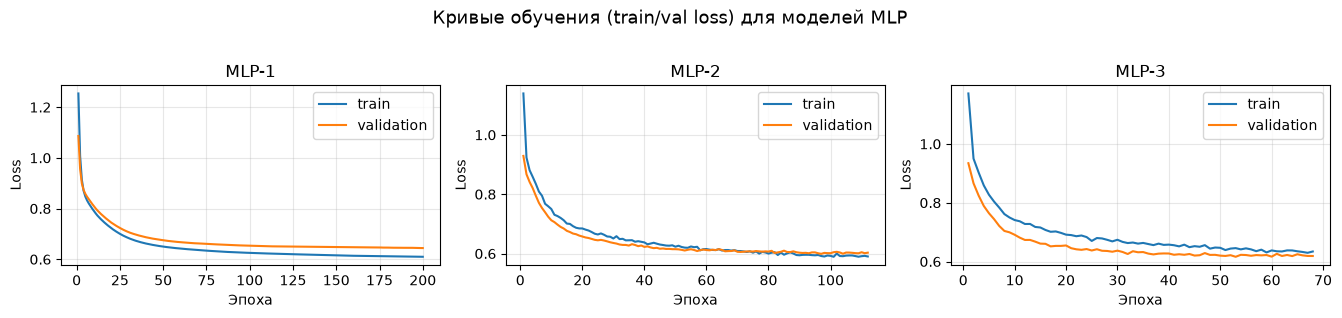

In [17]:
rows = []
for n, r in mc.items():
    for met in ["precision", "recall", "f1-score"]:
        rows.append({
            "Модель": n,
            "Метрика": met,
            **{c: r["rep"][CLASSES[c]][met] for c in range(K)},
            "Macro avg": r["rep"]["macro avg"][met],
            "Weighted avg": r["rep"]["weighted avg"][met]
        })

    rows.append({
        "Модель": n,
        "Метрика": "ROC-AUC (OvR)",
        **{c: a for c, a in zip(range(K), r["aucs"])},
        "Macro avg": r["macro_auc"],
        "Weighted avg": np.nan
    })

tabB = pd.DataFrame(rows)
tabB.rename(columns={c: CLASSES[c] for c in range(K)}, inplace=True)
print(tabB.round(4).to_string(index=False))

plot_histories(
    mc_hist,
    title="Кривые обучения (train/val loss) для моделей MLP"
)

Лучшая модель по Val Balanced Accuracy: MLP-3


Text(0.5, 1.0, 'MLP-3: ROC One-vs-Rest (test), macro AUC=0.929')

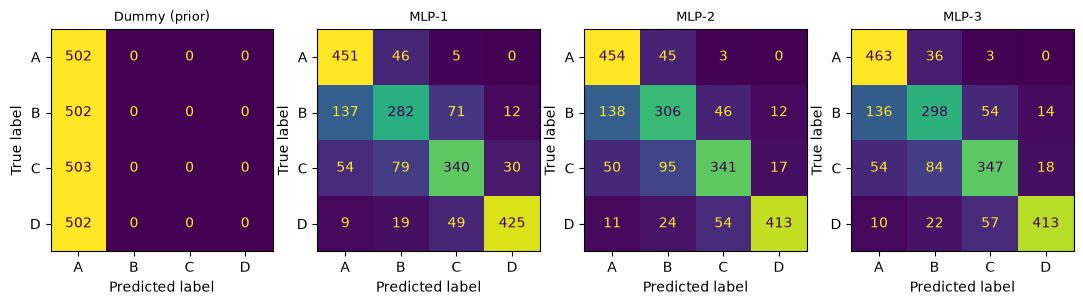

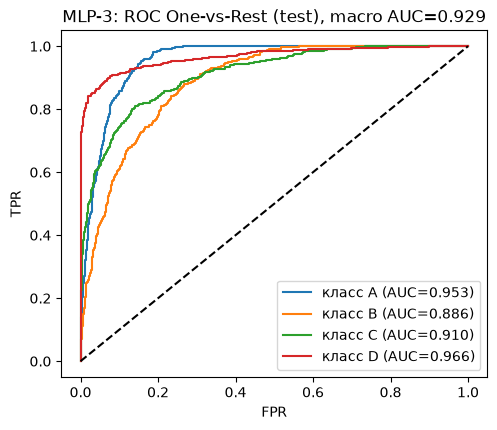

In [18]:
# Матрицы ошибок всех моделей
names = list(mc.keys()); fig, axs = plt.subplots(1, len(names), figsize=(3.3*len(names), 3.3))
for ax, n in zip(axs, names):
    ConfusionMatrixDisplay(confusion_matrix(yte_m, mc[n]["pred"]), display_labels=CLASSES).plot(ax=ax, colorbar=False); ax.set_title(n, fontsize=9)

# Лучшая модель по Val Balanced Accuracy и её ROC-кривые OvR
nn_names = [n for n in mc if n.startswith("MLP")]; mname = max(nn_names, key=lambda n: mc_val[n]["bal"])
print("Лучшая модель по Val Balanced Accuracy:", mname)
Y = label_binarize(yte_m, classes=list(range(K))); plt.figure(figsize=(5.5, 4.5))
for i, c in enumerate(CLASSES):
    f, t, _ = roc_curve(Y[:, i], mc_proba[mname][:, i]); plt.plot(f, t, label=f"класс {c} (AUC={mc[mname]['aucs'][i]:.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(); plt.title(f"{mname}: ROC One-vs-Rest (test), macro AUC={mc[mname]['macro_auc']:.3f}")
